# Figure 4 (v2) — ligand trajectories from ChronoPack NB-GAM fits

v1 (`../Fig4_C2C`) benchmarks THP1 → K562 ligand prioritization across ChronoPack, LIANA, CellChat,
NicheNet and TraSig. Its right-hand panels show, for each method's top 10 ligands, the THP1
per-time-point mean of the r9 `log1p` layer, next to K562 NFKBIA.

v2 changes only those panels: they now draw ChronoPack's NB-GAM (tradeSeq) fits on the r9 data.
- **THP1 ligands** (30, the top 10s of ChronoPack, LIANA, NicheNet and TraSig): one ChronoPack quick
  fit with the r9 THP1 inputs, offsets and 8 knots. `tag="full"` also fits the 6 ligands that the
  r9 tradeSeq inputs filtered out (marked † in the legends).
- **K562 NFKBIA**: the stored r9 K562 final fit.

The rankings, panels A–B and the manifest come from v1's tables (`input/v1/`) and are checked to be
identical. By default the notebook shows the existing outputs; set `RERUN = True` to regenerate.

## Setup

In [1]:
import os
import sys
from pathlib import Path

FIG_DIR = Path.cwd()  # the notebook runs from its figure folder
sys.path.insert(0, str(FIG_DIR / "scripts"))
from nb_helpers import needs_run, run, show_image, show_table, show_text

# False: show the existing outputs (steps only run if an output is missing).
# True:  regenerate every step. Batch runs can set FIG_RERUN=1 instead of editing this cell.
RERUN = os.environ.get("FIG_RERUN", "0") == "1"

CP_ENV = Path("/new-stg/home/alex/miniconda3/envs/chronopack")   # chronopack + rpy2/R (fits, figure)
CP_PYTHON = CP_ENV / "bin" / "python"
print("RERUN =", RERUN)

RERUN = False


## Step 01 — ChronoPack fitted curves

`01_fit_curves.py`:
1. Fits the 30 THP1 ligands with `cp.tl.fit_gene_dynamics(input_dir=input/thp1_tradeseq, genes=...,
   final_nknots=8, tag="full")`. This uses the same cells and offsets as the r9 final fit.
2. Predicts each curve and its 95% band over 0–165 min with `cp.tl.predict_gene_dynamics`. The
   values are log1p of the fitted mean count at the fit's reference library size: THP1 2,528 and
   K562 3,306 UMIs. NFKBIA comes from the stored r9 K562 fit `sce.1trajectory.nknots8.rds`.
3. Checks the 11 ligands that are in the stored r9 THP1 final fit against it. The step fails if
   any differs.

In [2]:
import pandas as pd

if needs_run(["output/chronopack/fitted_curves.csv", "output/chronopack/ligand_fit_summary.csv"], RERUN):
    run([CP_PYTHON, "scripts/01_fit_curves.py"], prepend_path=CP_ENV / "bin")
show_table("output/chronopack/ligand_fit_summary.csv", n=None);

Using existing outputs (set RERUN = True to regenerate).


,gene,cell_type,thp1_total_counts,in_r9_tradeseq_inputs,in_r9_final_fit,r9_screen_pvalue,quick_fit_pvalue,max_abs_diff_vs_r9_final_fit,fit_peak_min,fit_max_mu_log1p
0,APOE,THP1,4810.0,False,False,NaN,3.454850e-01,NaN,165.0,1.870198
1,CALM1,THP1,1749.0,True,True,0.002028,3.911357e-02,9.992007e-15,0.0,1.128530
2,CCL18,THP1,9.0,False,False,NaN,9.999994e-01,NaN,165.0,0.010862
3,CCL3,THP1,4145.0,True,True,0.000000,0.000000e+00,1.021405e-14,135.0,2.208702
4,CCL3L3,THP1,2365.0,True,True,0.000000,0.000000e+00,9.992007e-15,151.0,1.756346
5,CCL4,THP1,7982.0,True,True,0.000000,0.000000e+00,1.021405e-14,165.0,3.122559
6,CCL5,THP1,1211.0,True,True,0.000000,2.220446e-16,9.992007e-16,165.0,1.212168
7,CTSG,THP1,91.0,True,False,0.469258,9.186885e-01,NaN,66.0,0.107403
8,CXCL1,THP1,2088.0,True,True,0.000000,0.000000e+00,9.992007e-15,165.0,1.766139
9,CXCL2,THP1,675.0,True,True,0.000000,0.000000e+00,9.992007e-16,82.0,0.884127


## Step 02 — the figure

This is v1's plotting script with one change: the trajectory panels read step 01's curves. Panel A
(TNF/TNFR rank) and panel B (early log2FC, 45 vs 0 min, from the `log1p` layer) are unchanged.

Using existing outputs (set RERUN = True to regenerate).


**Fig4 v2: trajectories from ChronoPack NB-GAM fits (r9)** — `output/figures/fig4_v2_composite_temporal_prioritization.png`

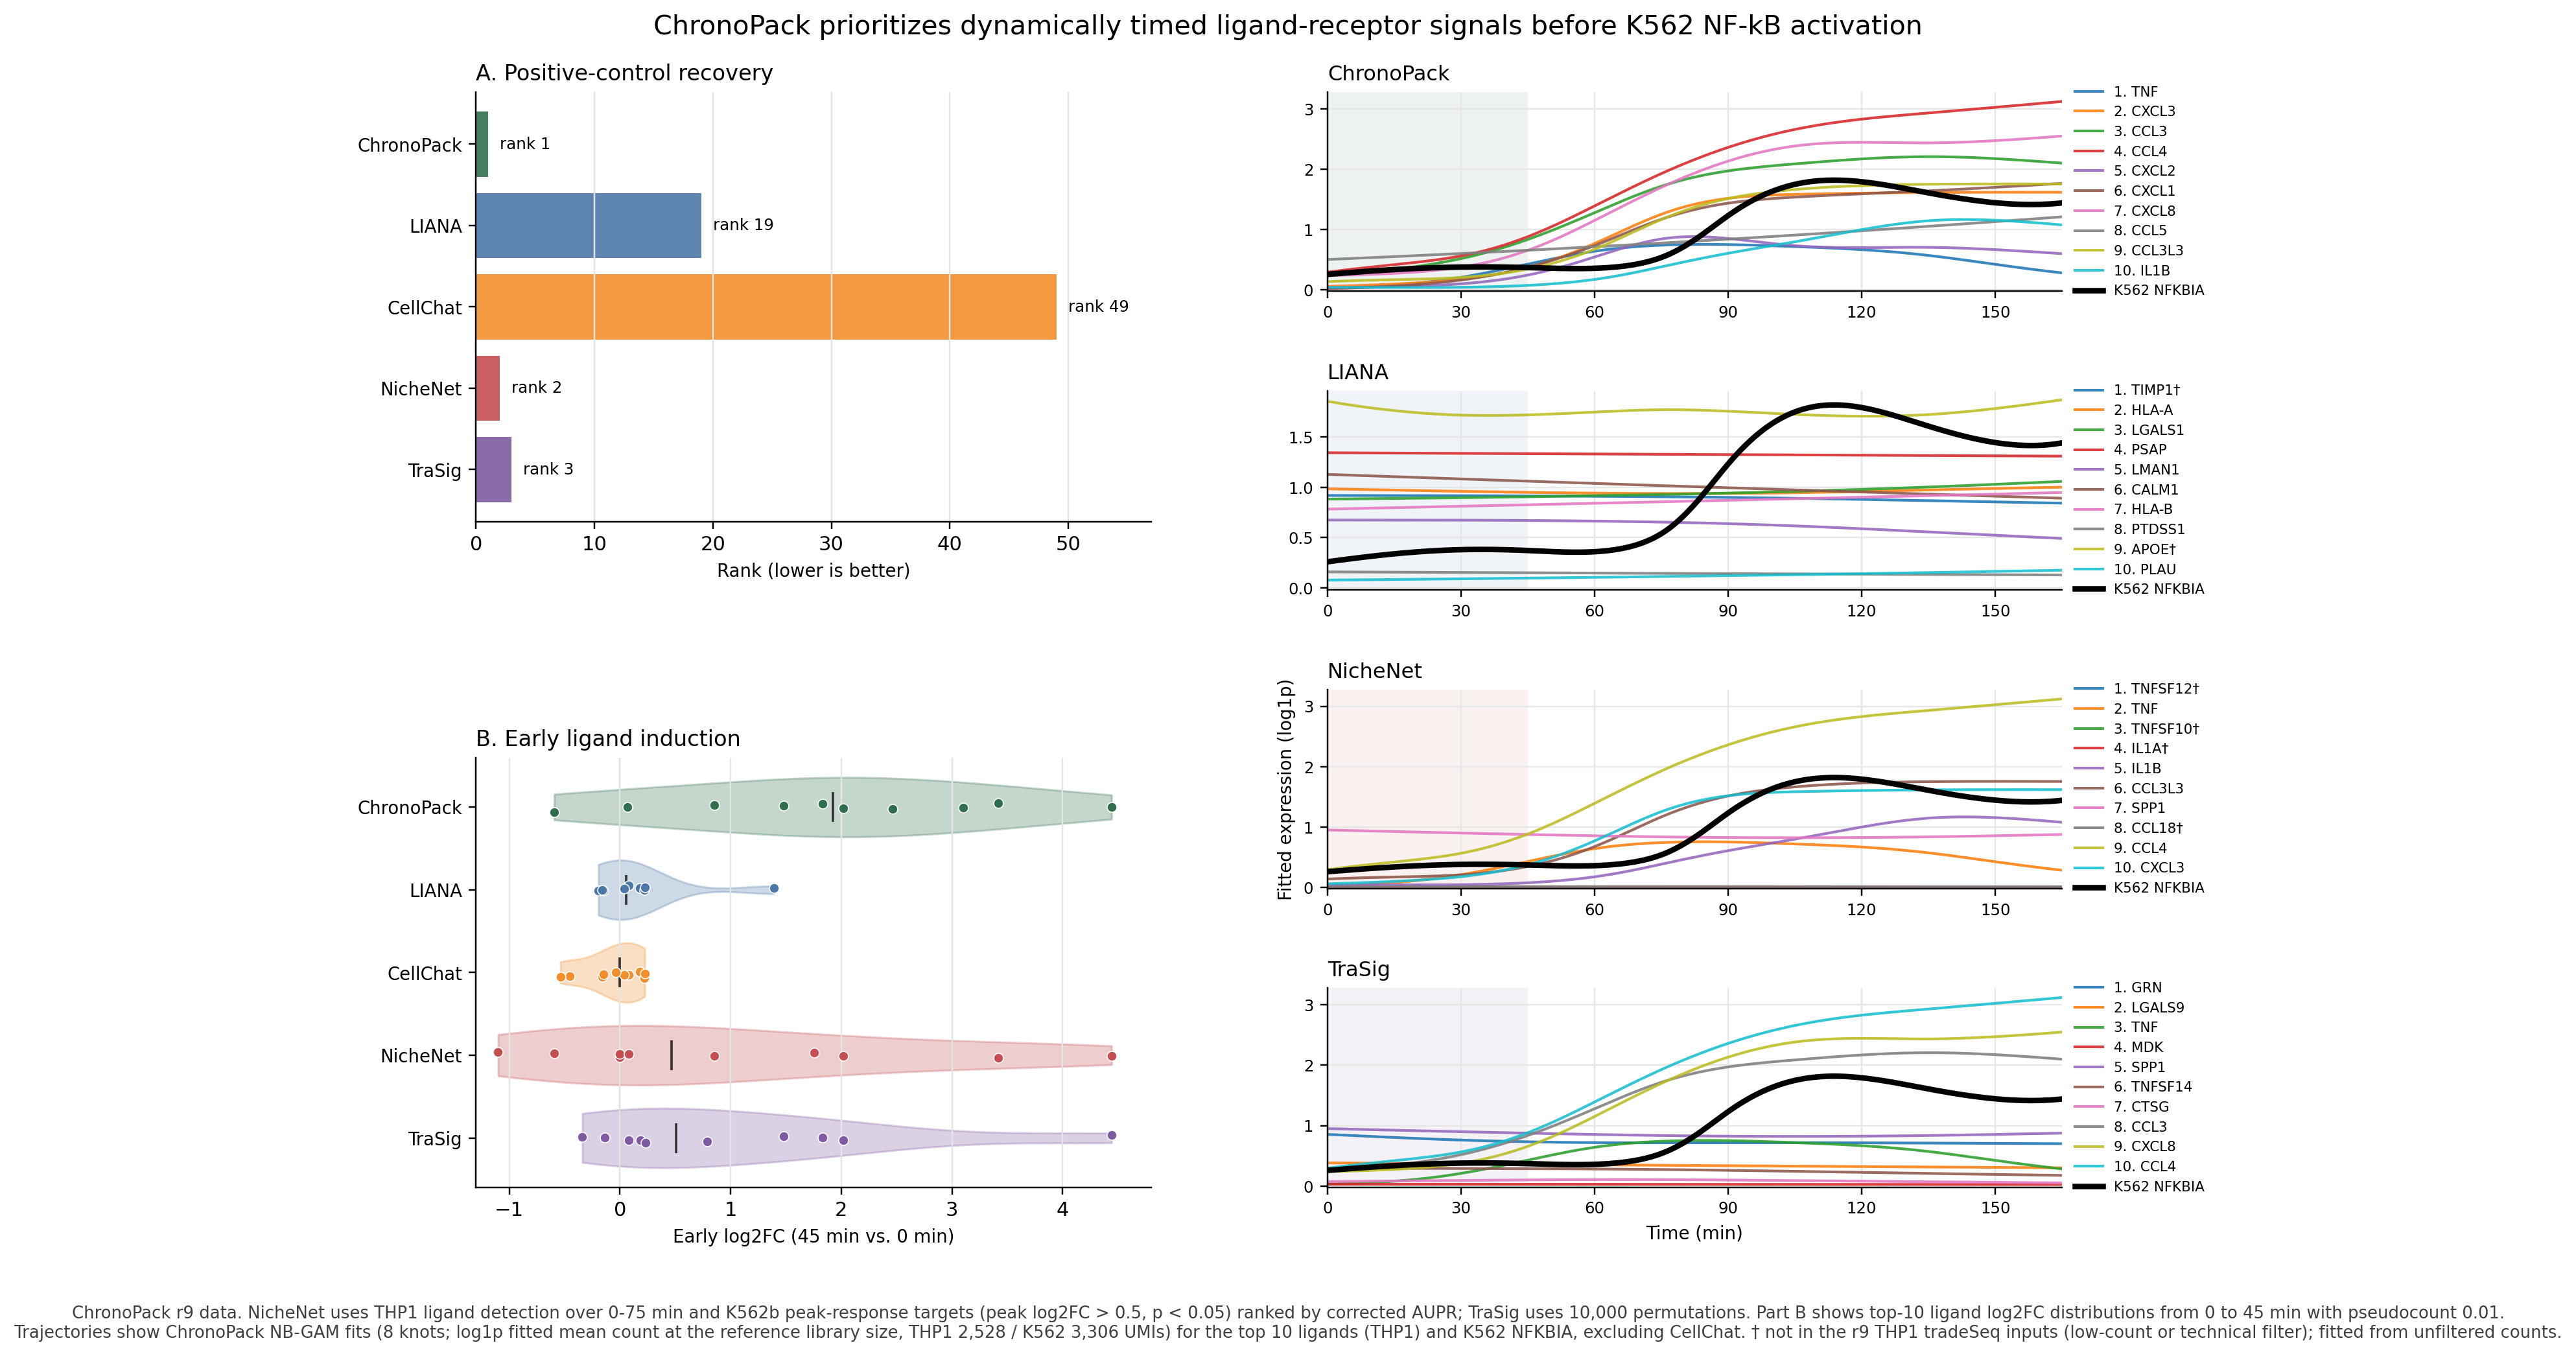

In [3]:
fig = "output/figures/fig4_v2_composite_temporal_prioritization"
if needs_run([fig + ".png", fig + "_manifest.csv"], RERUN):
    run([CP_PYTHON, "scripts/02_plot_fig4_v2.py"], prepend_path=CP_ENV / "bin")
show_image(fig + ".png", caption="Fig4 v2: trajectories from ChronoPack NB-GAM fits (r9)")

## Step 03 — comparison with v1

The report has four parts:
1. Whether the manifest and positive-control ranks are identical to v1's.
2. The quick-fit check against the stored r9 fit.
3. Each fitted curve against v1's per-time-point means: Pearson r over the 12 time points, and the
   peak minute of each.
4. How many of each method's top 10 ligands peak in the 0–45 min window.

Flat, non-dynamic ligands, mostly LIANA's and TraSig's, get low r. For them the fit smooths out
time-point noise, so their peak minute is not meaningful.

In [4]:
if needs_run(["output/comparison_to_v1.txt"], RERUN):
    run([CP_PYTHON, "scripts/03_compare_to_v1.py"], prepend_path=CP_ENV / "bin")
show_text("output/comparison_to_v1.txt")

Using existing outputs (set RERUN = True to regenerate).
